In [223]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf
from matplotlib import colors
import geopandas as gpd
import pandas as pd
import rioxarray
import xproj
import xvec

# plotting function
def plot_map(dataarray, title='', cmap='viridis', cmap_split = '', discrete_cmap=0, vmin=None, vmax=None, borders=False, norm=None, cbar_label= '', cbar_loc = 'bottom', svg=False, grid_labels=False, local_map=False):
    
    if cmap_split=='low':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.0, 0.5)
    elif cmap_split=='high':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.5, 1.0)
    elif cmap_split=='trim':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.1, 0.9)
    else:
        custom_cmap = plt.get_cmap(cmap)

    if discrete_cmap != 0:
        custom_cmap = discrete_colormap(custom_cmap, discrete_cmap)

    if cbar_label=='':
        cbar_label = dataarray.name
        
    plt.figure(figsize=(12, 8))
    if local_map == False:
        ax = plt.axes(projection=ccrs.Robinson())
    else: # for local maps use PlateCarree projection
        ax = plt.axes(projection=ccrs.PlateCarree())
    # plot only nans in grey. supress cbar
    xr.where(dataarray.isnull(), 1, np.nan).plot(ax=ax, cmap=colors.ListedColormap(['lightgrey']), vmin=1, vmax=1, transform=ccrs.PlateCarree(), add_colorbar=False)
    # plot data
    dataarray.plot(ax=ax, cmap=custom_cmap, vmin=vmin, vmax=vmax, norm=norm, cbar_kwargs={'label': cbar_label, 'location': cbar_loc, 'fraction': 0.06, 'pad': 0.05, 'ticks': np.linspace(vmin + (vmin/discrete_cmap), vmax + (vmax/discrete_cmap), int((discrete_cmap + 1)/2)+1) if discrete_cmap else None}, transform=ccrs.PlateCarree())    
    ax.coastlines() # coastlines for context

    ax.add_feature(cf.OCEAN, facecolor='white', zorder=5)
    if borders: # country borders toggle
        ax.add_feature(cf.BORDERS)

    if grid_labels:
        # show only major longitude/latitude labels using gridlines
        lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
        lat_ticks = [-45, -30, -15, 0, 15, 30, 45]

        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0,
            x_inline=False,
            y_inline=False,
        )
        # show only bottom and left labels
        gl.top_labels = False
        gl.right_labels = False
        gl.bottom_labels = True
        gl.left_labels = True
        gl.xlocator = FixedLocator(lon_ticks)
        gl.ylocator = FixedLocator(lat_ticks)
        gl.xformatter = LongitudeFormatter()
        gl.yformatter = LatitudeFormatter()
        gl.xlabel_style = {'size': 10}
        gl.ylabel_style = {'size': 10}

    ax.set_title(title)
    if svg:
        plt.savefig("../export/map_{}.svg".format(dataarray.name), format='svg', bbox_inches='tight')
    plt.show()

# convert a continous cmap to a graduated discrete cmap with n discrete colors. eg, 5 discrete colors from a continuous cmap
def discrete_colormap(cmap, n):
    cmap = plt.get_cmap(cmap)
    new_cmap = colors.ListedColormap(
        cmap(np.linspace(0, 1, n)))
    return new_cmap

In [208]:
# load IPCC reference regions (geojson) for subcontinental aggregated analysis
ipcc_regions = gpd.read_file('../data-raw/IPCC-WGI-reference-regions-v4.geojson')

In [185]:
ipcc_regions

,id,Continent,Type,Name,Acronym,geometry
0,0,POLAR,Land,Greenland/Iceland,GIC,"POLYGON ((-10 62, -10.4375 62, -10.875 62, -11..."
1,1,NORTH-AMERICA,Land,N.W.North-America,NWN,"POLYGON ((-105 50, -105.4386 50, -105.87719 50..."
2,2,NORTH-AMERICA,Land,N.E.North-America,NEN,"POLYGON ((-50 50, -50.44 50, -50.88 50, -51.32..."
3,3,NORTH-AMERICA,Land,W.North-America,WNA,"POLYGON ((-130 50, -129.5614 50, -129.12281 50..."
4,4,NORTH-AMERICA,Land,C.North-America,CNA,"POLYGON ((-90 50, -90 49.5614, -90 49.12281, -..."
5,5,NORTH-AMERICA,Land,E.North-America,ENA,"POLYGON ((-70 25, -70.43478 25, -70.86957 25, ..."
6,6,CENTRAL-AMERICA,Land,N.Central-America,NCA,"POLYGON ((-90 25, -90.37179 24.76923, -90.7435..."
7,7,CENTRAL-AMERICA,Land,S.Central-America,SCA,"POLYGON ((-75 12, -75.28 11.67333, -75.56 11.3..."
8,8,CENTRAL-AMERICA,Land-Ocean,Caribbean,CAR,"POLYGON ((-75 12, -75.32609 12.28261, -75.6521..."
9,9,SOUTH-AMERICA,Land,N.W.South-America,NWS,"POLYGON ((-75 12, -74.57143 12, -74.14286 12, ..."


In [209]:
# ml-predicted SR for different periods
sr_1901_1930 = xr.open_dataarray("../export/sr_1901_1930.nc")
sr_1931_1960 = xr.open_dataarray("../export/sr_1931_1960.nc")
sr_1961_1990 = xr.open_dataarray("../export/sr_1961_1990.nc")
sr_1991_2020 = xr.open_dataarray("../export/sr_1991_2020.nc")

In [210]:
# create dataset with all periods
sr_ds = xr.Dataset({
    'SR_1901_1930': sr_1901_1930,
    'SR_1931_1960': sr_1931_1960,
    'SR_1961_1990': sr_1961_1990,
    'SR_1991_2020': sr_1991_2020
})

In [255]:
sr_ds

<xarray.Dataset> Size: 300MB
Dimensions:       (lat: 2600, lon: 7200)
Coordinates:
  * lat           (lat) float64 21kB 74.38 74.33 74.28 ... -55.48 -55.52 -55.58
  * lon           (lon) float64 58kB -180.0 -179.9 -179.9 ... 179.9 179.9 180.0
Data variables:
    SR_1901_1930  (lat, lon) float32 75MB ...
    SR_1931_1960  (lat, lon) float32 75MB ...
    SR_1961_1990  (lat, lon) float32 75MB ...
    SR_1991_2020  (lat, lon) float32 75MB ...

In [254]:
# switch lat order from ascending to descending for plotting
sr_ds = sr_ds.sortby('lat', ascending=False)

In [216]:
ipcc_regions.geometry

0     POLYGON ((-10 62, -10.4375 62, -10.875 62, -11...
1     POLYGON ((-105 50, -105.4386 50, -105.87719 50...
2     POLYGON ((-50 50, -50.44 50, -50.88 50, -51.32...
3     POLYGON ((-130 50, -129.5614 50, -129.12281 50...
4     POLYGON ((-90 50, -90 49.5614, -90 49.12281, -...
5     POLYGON ((-70 25, -70.43478 25, -70.86957 25, ...
6     POLYGON ((-90 25, -90.37179 24.76923, -90.7435...
7     POLYGON ((-75 12, -75.28 11.67333, -75.56 11.3...
8     POLYGON ((-75 12, -75.32609 12.28261, -75.6521...
9     POLYGON ((-75 12, -74.57143 12, -74.14286 12, ...
10    POLYGON ((-72 12, -71.5641 12, -71.12821 12, -...
11    POLYGON ((-34 -20, -34.43243 -20, -34.86486 -2...
12    POLYGON ((-66.4 -20, -66.71111 -19.72222, -67....
13    POLYGON ((-72 -15, -71.68889 -15.27778, -71.37...
14    POLYGON ((-34 -20, -34.32353 -20.29412, -34.64...
15    POLYGON ((-79 -56, -79 -55.57143, -79 -55.1428...
16    POLYGON ((-10 48, -10 48.43929, -10 48.87857, ...
17    POLYGON ((-10 45, -10 45.42857, -10 45.857

In [260]:
# sample ml sr within the ipcc region as mean values for each region. add columns to the ipcc_regions geodataframe
# use zonal_stats from xvec package to sample the xarray data within the polygons of the ipcc_regions geodataframe
regional_sr = sr_ds.xvec.zonal_stats(ipcc_regions.geometry, x_coords='lon', y_coords='lat', stats='mean')

In [261]:
regional_sr_df = regional_sr.to_dataframe()
# flatten the multi-index columns. "zonal_statistics" is the top level, and "mean" is the second level
# we want to make "zonal_statistics" the column name and "mean" the column values. we can do this by using the reset_index() method and then renaming the columns
regional_sr_df = regional_sr_df.reset_index()

In [262]:
# copy other columns from ipcc_regions (without geometry) to regional_sr_df. we can do this by using the merge() method and merging on the index
regional_sr_df = regional_sr_df.merge(ipcc_regions.drop(columns='geometry'), left_index=True, right_index=True)

In [263]:
regional_sr_df

,geometry,SR_1901_1930,SR_1931_1960,SR_1961_1990,SR_1991_2020,id,Continent,Type,Name,Acronym
0,"POLYGON ((-10 62, -10.4375 62, -10.875 62, -11...",NaN,NaN,NaN,NaN,0,POLAR,Land,Greenland/Iceland,GIC
1,"POLYGON ((-105 50, -105.4386 50, -105.87719 50...",NaN,NaN,NaN,NaN,1,NORTH-AMERICA,Land,N.W.North-America,NWN
2,"POLYGON ((-50 50, -50.44 50, -50.88 50, -51.32...",NaN,NaN,NaN,NaN,2,NORTH-AMERICA,Land,N.E.North-America,NEN
3,"POLYGON ((-130 50, -129.5614 50, -129.12281 50...",NaN,NaN,NaN,NaN,3,NORTH-AMERICA,Land,W.North-America,WNA
4,"POLYGON ((-90 50, -90 49.5614, -90 49.12281, -...",NaN,NaN,NaN,NaN,4,NORTH-AMERICA,Land,C.North-America,CNA
5,"POLYGON ((-70 25, -70.43478 25, -70.86957 25, ...",NaN,NaN,NaN,NaN,5,NORTH-AMERICA,Land,E.North-America,ENA
6,"POLYGON ((-90 25, -90.37179 24.76923, -90.7435...",NaN,NaN,NaN,NaN,6,CENTRAL-AMERICA,Land,N.Central-America,NCA
7,"POLYGON ((-75 12, -75.28 11.67333, -75.56 11.3...",NaN,NaN,NaN,NaN,7,CENTRAL-AMERICA,Land,S.Central-America,SCA
8,"POLYGON ((-75 12, -75.32609 12.28261, -75.6521...",NaN,NaN,NaN,NaN,8,CENTRAL-AMERICA,Land-Ocean,Caribbean,CAR
9,"POLYGON ((-75 12, -74.57143 12, -74.14286 12, ...",NaN,NaN,NaN,NaN,9,SOUTH-AMERICA,Land,N.W.South-America,NWS


In [ ]:
# alternative: use xarray-spatial for zonal stats


In [2]:
lpjml1 = xr.open_dataset('../data-raw/ISIMIP/rootmoist/obsclim_histsoc/lpjml5-7-10-fire_gswp3-w5e5_obsclim_histsoc_default_rootmoist_global_monthly_1901_2019.nc')
# depth integration to get the total root moisture content in the soil column in mm
# rootmoist is in kg/m2 (= mm), so simply add the values for each layer to get the total root moisture content in the soil column in mm
rm = lpjml1.rootmoist.sum(dim='depth')
rm = rm.sel(lat=slice(75, -60))

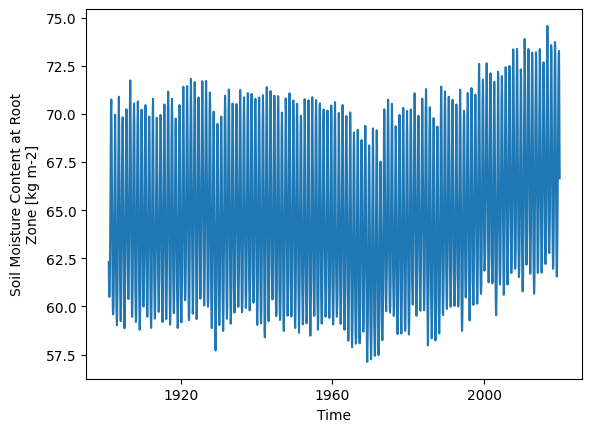

In [3]:
rm.mean(dim='lat').mean(dim='lon').plot()

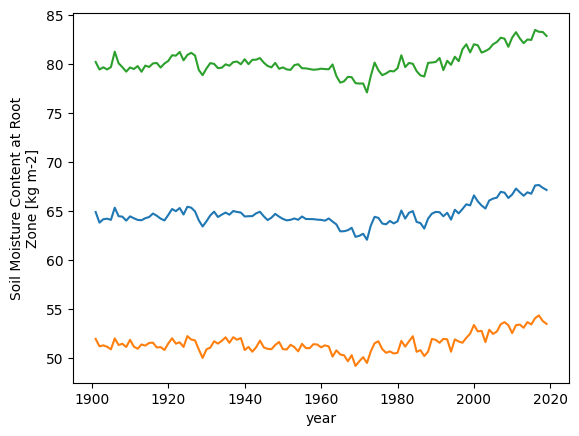

In [4]:
# plot annualglobal mean as a line plot with annual min max as shaded area
rm_annual = rm.groupby('time.year').mean(dim='time').mean(dim=['lat', 'lon'])
rm_annual_min = rm.groupby('time.year').min(dim='time').mean(dim=['lat', 'lon'])
rm_annual_max = rm.groupby('time.year').max(dim='time').mean(dim=['lat', 'lon'])

rm_annual.plot()
rm_annual_min.plot()
rm_annual_max.plot()

In [79]:
# period mean, p95, max
rm_1901_1930_mean = rm.sel(time=slice('1901-01-01', '1930-12-31')).mean(dim='time')
rm_1931_1960_mean = rm.sel(time=slice('1931-01-01', '1960-12-31')).mean(dim='time')
rm_1961_1990_mean = rm.sel(time=slice('1961-01-01', '1990-12-31')).mean(dim='time')
rm_1991_2020_mean = rm.sel(time=slice('1991-01-01', '2019-12-31')).mean(dim='time')

rm_1901_1930_p95 = rm.sel(time=slice('1901-01-01', '1930-12-31')).quantile(0.95, dim='time')
rm_1931_1960_p95 = rm.sel(time=slice('1931-01-01', '1960-12-31')).quantile(0.95, dim='time')
rm_1961_1990_p95 = rm.sel(time=slice('1961-01-01', '1990-12-31')).quantile(0.95, dim='time')
rm_1991_2020_p95 = rm.sel(time=slice('1991-01-01', '2019-12-31')).quantile(0.95, dim='time')

rm_1901_1930_max = rm.sel(time=slice('1901-01-01', '1930-12-31')).max(dim='time')
rm_1931_1960_max = rm.sel(time=slice('1931-01-01', '1960-12-31')).max(dim='time')
rm_1961_1990_max = rm.sel(time=slice('1961-01-01', '1990-12-31')).max(dim='time')
rm_1991_2020_max = rm.sel(time=slice('1991-01-01', '2019-12-31')).max(dim='time')

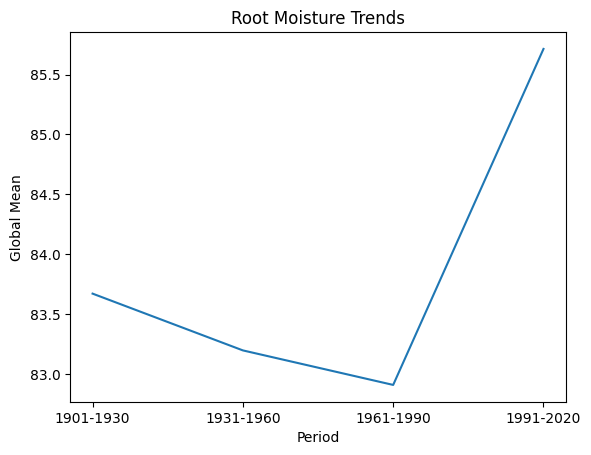

In [6]:
# plot global mean for each period
rm_1901_1930_global_p95 = rm_1901_1930_p95.mean(dim=['lat', 'lon'])
rm_1931_1960_global_p95 = rm_1931_1960_p95.mean(dim=['lat', 'lon'])
rm_1961_1990_global_p95 = rm_1961_1990_p95.mean(dim=['lat', 'lon'])
rm_1991_2020_global_p95 = rm_1991_2020_p95.mean(dim=['lat', 'lon'])

# line plot of global mean for each period
import matplotlib.pyplot as plt
plt.plot(['1901-1930', '1931-1960', '1961-1990', '1991-2020'], [rm_1901_1930_global_p95, rm_1931_1960_global_p95, rm_1961_1990_global_p95, rm_1991_2020_global_p95])
plt.xlabel('Period')
plt.ylabel('Global Mean')
plt.title('Root Moisture Trends')
plt.show()

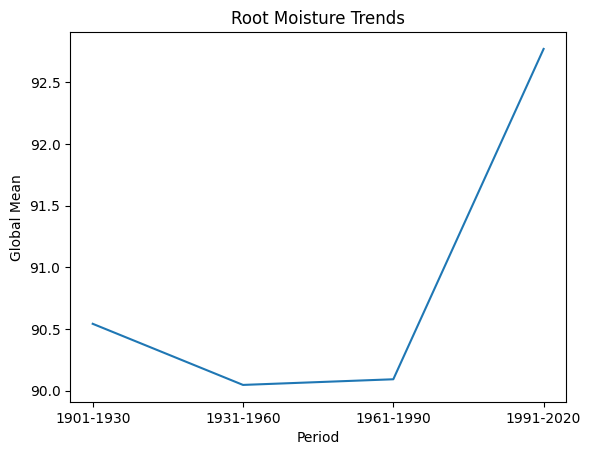

In [ ]:
# plot global mean of max rm for each period
rm_1901_1930_global_max = rm_1901_1930_max.mean(dim=['lat', 'lon'])
rm_1931_1960_global_max = rm_1931_1960_max.mean(dim=['lat', 'lon'])
rm_1961_1990_global_max = rm_1961_1990_max.mean(dim=['lat', 'lon'])
rm_1991_2020_global_max = rm_1991_2020_max.mean(dim=['lat', 'lon'])

# line plot of global mean for each period
import matplotlib.pyplot as plt
plt.plot(['1901-1930', '1931-1960', '1961-1990', '1991-2020'], [rm_1901_1930_global_max, rm_1931_1960_global_max, rm_1961_1990_global_max, rm_1991_2020_global_max])
plt.xlabel('Period')
plt.ylabel('Global Mean')
plt.title('Root Moisture Trends')
plt.show()

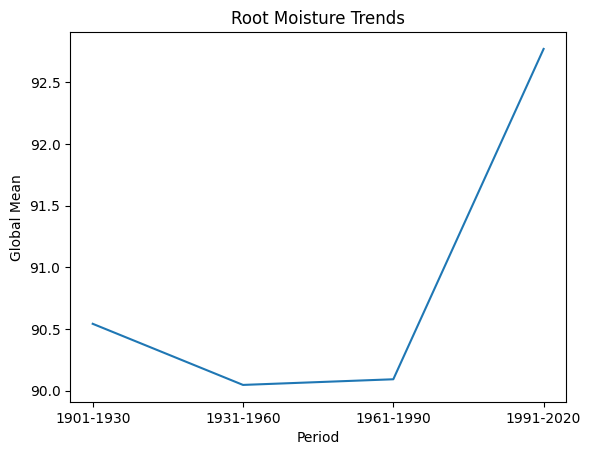

In [81]:
# plot global mean of p95 rm for each period
rm_1901_1930_global_p95 = rm_1901_1930_p95.mean(dim=['lat', 'lon'])
rm_1931_1960_global_p95 = rm_1931_1960_p95.mean(dim=['lat', 'lon'])
rm_1961_1990_global_p95 = rm_1961_1990_p95.mean(dim=['lat', 'lon'])
rm_1991_2020_global_p95 = rm_1991_2020_p95.mean(dim=['lat', 'lon'])

# line plot of global mean for each period
import matplotlib.pyplot as plt
plt.plot(['1901-1930', '1931-1960', '1961-1990', '1991-2020'], [rm_1901_1930_global_max, rm_1931_1960_global_max, rm_1961_1990_global_max, rm_1991_2020_global_max])
plt.xlabel('Period')
plt.ylabel('Global Mean')
plt.title('Root Moisture Trends')
plt.show()

In [ ]:
# get the annual series of max rm for each year (1901-2019), and calculate 20-year moving window max from 1921 to 2019
rm_annual_max = rm.groupby('time.year').max(dim='time')
rm_annual_max_global_mean = rm_annual_max.mean(dim=['lat', 'lon'])
rm_annual_max_20yr_global_mean = rm_annual_max_global_mean.rolling(year=20, center=True).max().dropna(dim='year')

In [146]:
# annual series of p02 rm
rm_annual_p05 = rm.groupby('time.year').quantile(0.05, dim='time')

# annual series of median rm
rm_annual_median = rm.groupby('time.year').quantile(0.5, dim='time')

In [115]:
rm_annual_max

<xarray.DataArray 'rootmoist' (year: 119, lat: 270, lon: 720)> Size: 93MB
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
...
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]],
      shape=(119, 270, 720), dtype=float32)
Coordinates:
  * year     (year) int64 952B 1901 1902 1903 1904 1905 ... 2016 2017 2018 2019
  * lat      (lat) float64 2kB 74.75 74.25 73.75 73.25 ... -58.75 -59.25 -59.75
  * lon      (lon) float64 6kB -179.8 -179.2 -178.8 -178.2 ... 178.8 179.2 179.8
Attributes:
    standard_name:  rootmoist
    units:          kg m-2
    long_name:      Soil Moisture Content at Root Zone

In [122]:
# regional means
# amazon
rm_annual_max.sel(lat=slice(0, -10), lon=slice(-70, -60)).mean(dim=['lat', 'lon']).values

array([556.8968 , 557.5562 , 555.2981 , 555.8112 , 554.17303, 553.3874 ,
       553.71796, 559.0896 , 560.44446, 560.53485, 560.5117 , 543.4443 ,
       560.4947 , 560.5982 , 559.0467 , 558.37964, 559.99066, 560.05237,
       555.0666 , 559.94183, 560.69934, 560.7412 , 560.7759 , 560.6977 ,
       560.69086, 553.26245, 557.1    , 560.6884 , 560.26605, 559.52936,
       560.6526 , 560.8066 , 560.79834, 560.82294, 560.7667 , 560.8041 ,
       560.8174 , 560.81006, 560.8273 , 560.6217 , 557.9814 , 559.88275,
       560.81036, 560.81036, 560.7588 , 560.7986 , 560.6124 , 560.7858 ,
       560.8331 , 560.8185 , 560.828  , 560.73035, 560.76447, 560.7797 ,
       560.7653 , 560.7494 , 560.6669 , 560.72314, 560.6864 , 560.7117 ,
       560.7513 , 560.8116 , 560.7255 , 560.31445, 560.46106, 560.74866,
       558.24475, 555.22327, 555.6706 , 560.767  , 560.84534, 560.8762 ,
       560.92   , 560.90955, 560.9054 , 560.9349 , 560.90814, 560.9041 ,
       559.8474 , 560.01447, 560.46454, 560.9128 , 

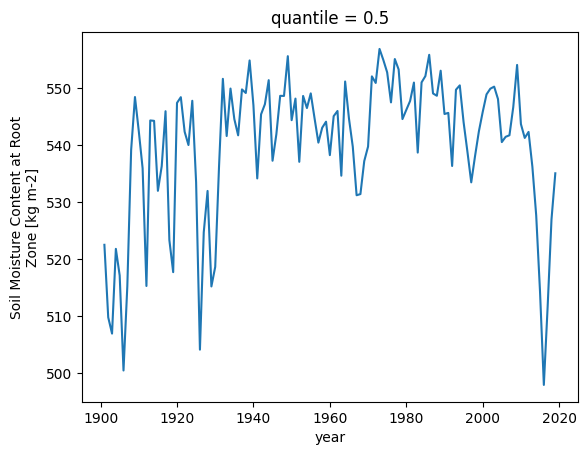

In [148]:
rm_annual_median.sel(lat=slice(0, -10), lon=slice(-70, -60)).mean(dim=['lat', 'lon']).plot()

In [149]:
rm_ratio = (rm_annual_median/rm_annual_p05)
# fill inf with nan
rm_ratio = rm_ratio.where(np.isfinite(rm_ratio), np.nan)

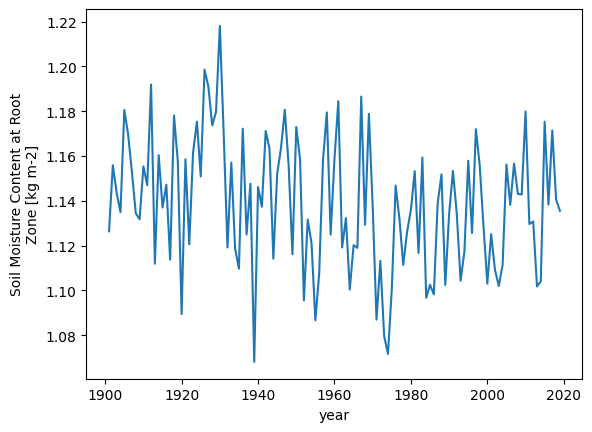

In [156]:
rm_ratio.sel(lat=slice(0, -10), lon=slice(-70, -60)).mean(dim=['lat', 'lon']).plot()

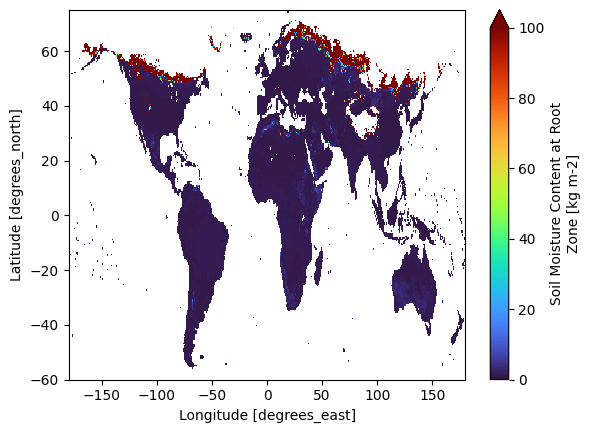

In [161]:
rm_ratio_1901_1930.plot(vmin=0, vmax=100, cmap='turbo')

In [150]:
rm_ratio_1901_1930 = rm_ratio.sel(year=slice(1901, 1930)).mean(dim=['year'])
rm_ratio_1931_1960 = rm_ratio.sel(year=slice(1931, 1960)).mean(dim=['year'])
rm_ratio_1961_1990 = rm_ratio.sel(year=slice(1961, 1990)).mean(dim=['year'])
rm_ratio_1991_2020 = rm_ratio.sel(year=slice(1991, 2020)).mean(dim=['year'])

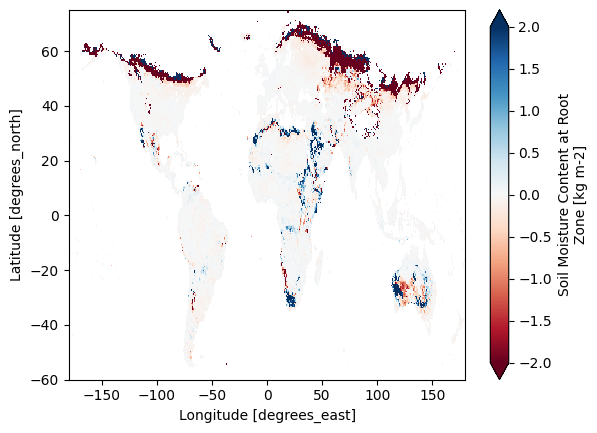

In [154]:
(rm_ratio_1991_2020 - rm_ratio_1901_1930).plot(vmin=-2, vmax=2, cmap='RdBu')

In [162]:
# for each year in each pixel, calculate the gini coefficient of daily rootmoist
# result is a annual series of gini coefficient for each pixel (119 years, 1440 lat, 720 lon)
def gini(x):
    # Calculate the Gini coefficient for a 1D array
    x = np.sort(x)
    n = len(x)
    if n <= 1:
        return 0
    return (2 * np.sum(np.arange(1, n + 1) * x) - (n + 1) * np.sum(x)) / (n * np.sum(x))

# apply the gini function to each pixel for each year
rm_gini = rm.groupby('time.year').apply(lambda x: xr.apply_ufunc(gini, x, input_core_dims=[['time']], vectorize=True, dask='parallelized', output_dtypes=[float]))

In [166]:
rm_gini_1901_1930 = rm_gini.sel(year=slice(1901, 1930)).mean(dim=['year'])
rm_gini_1931_1960 = rm_gini.sel(year=slice(1931, 1960)).mean(dim=['year'])
rm_gini_1961_1990 = rm_gini.sel(year=slice(1961, 1990)).mean(dim=['year'])
rm_gini_1991_2020 = rm_gini.sel(year=slice(1991, 2020)).mean(dim=['year'])

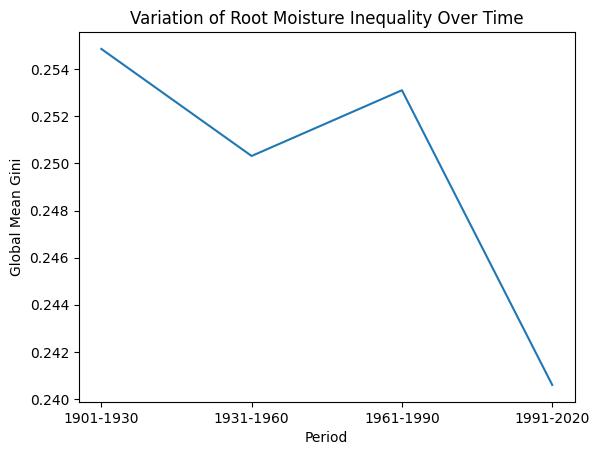

In [169]:
# plot global mean gini for 4 periods as a line plot
rm_gini_1901_1930_global_mean = rm_gini_1901_1930.mean(dim=['lat', 'lon'])
rm_gini_1931_1960_global_mean = rm_gini_1931_1960.mean(dim=['lat', 'lon'])
rm_gini_1961_1990_global_mean = rm_gini_1961_1990.mean(dim=['lat', 'lon'])
rm_gini_1991_2020_global_mean = rm_gini_1991_2020.mean(dim=['lat', 'lon'])

# line plot of global mean for each period
import matplotlib.pyplot as plt
plt.plot(['1901-1930', '1931-1960', '1961-1990', '1991-2020'], [rm_gini_1901_1930_global_mean, rm_gini_1931_1960_global_mean, rm_gini_1961_1990_global_mean, rm_gini_1991_2020_global_mean])
plt.xlabel('Period')
plt.ylabel('Global Mean Gini')
plt.title('Variation of Root Moisture Inequality Over Time')
plt.show()

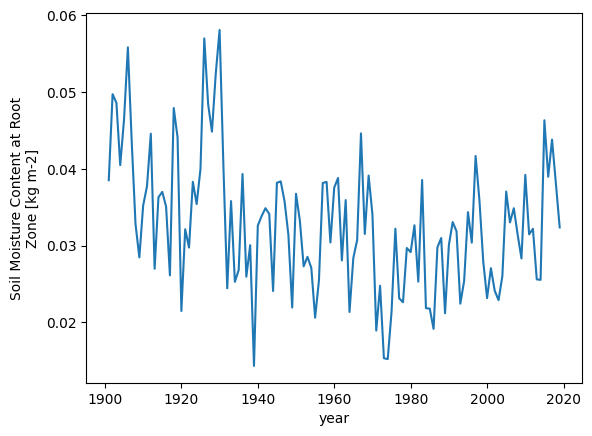

In [170]:
# gini series in amazon
rm_gini.sel(lat=slice(0, -10), lon=slice(-70, -60)).mean(dim=['lat', 'lon']).plot()

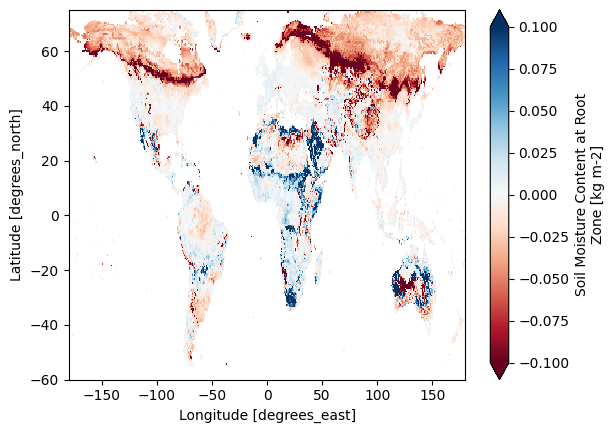

In [167]:
(rm_gini_1991_2020 - rm_gini_1901_1930).plot(vmin=-0.1, vmax=0.1, cmap='RdBu')

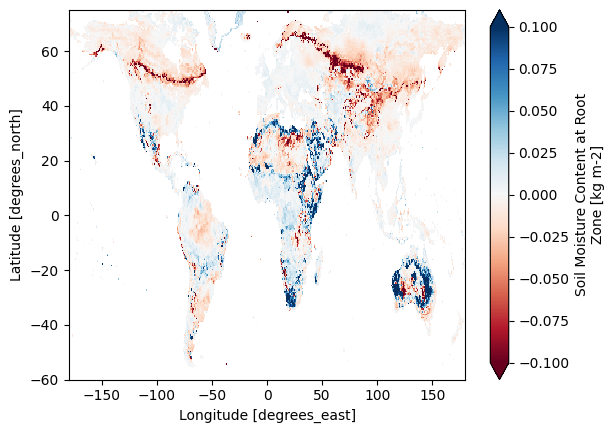

In [171]:
(rm_gini_1961_1990 - rm_gini_1901_1930).plot(vmin=-0.1, vmax=0.1, cmap='RdBu')

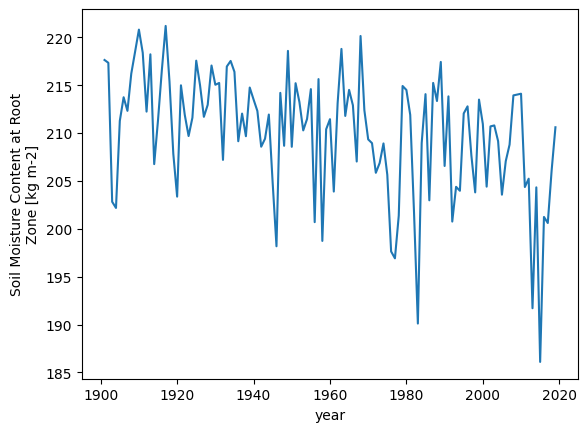

In [121]:
# sahel
rm_annual_max.sel(lat=slice(10, 0), lon=slice(-10, 10)).mean(dim=['lat', 'lon']).plot()

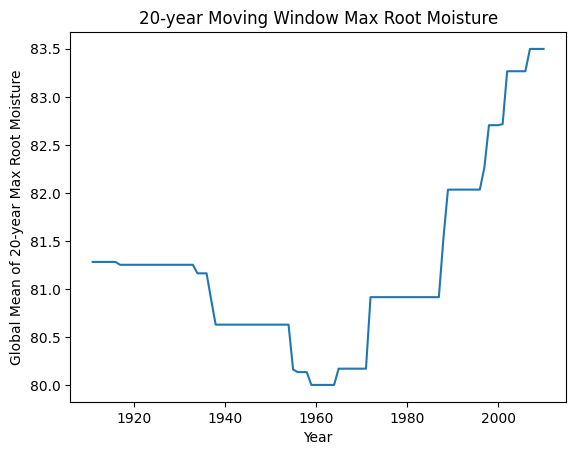

In [88]:
# global mean of 20yr max rm, plotted as a line plot
plt.plot(rm_annual_max_20yr_global_mean.year, rm_annual_max_20yr_global_mean)
plt.xlabel('Year')
plt.ylabel('Global Mean of 20-year Max Root Moisture')
plt.title('20-year Moving Window Max Root Moisture')
plt.show()

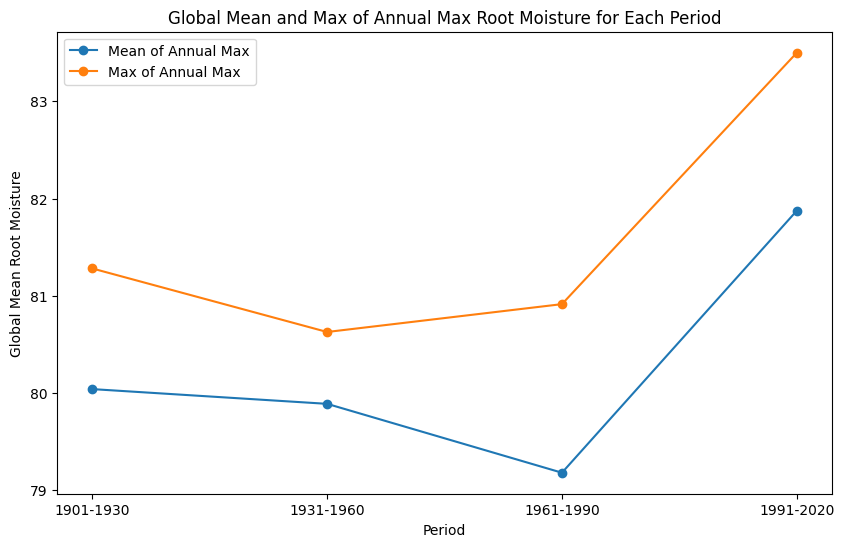

In [99]:
# period means of rm annual max series in 1901-1930, 1931-1960, 1961-1990, 1991-2020
rm_annual_max_mean_1901_1930 = rm_annual_max_global_mean.sel(year=slice(1901, 1930)).mean(dim='year')
rm_annual_max_mean_1931_1960 = rm_annual_max_global_mean.sel(year=slice(1931, 1960)).mean(dim='year')
rm_annual_max_mean_1961_1990 = rm_annual_max_global_mean.sel(year=slice(1961, 1990)).mean(dim='year')
rm_annual_max_mean_1991_2020 = rm_annual_max_global_mean.sel(year=slice(1991, 2020)).mean(dim='year')

# period max of rm annual max series in 1901-1930, 1931-1960, 1961-1990, 1991-2020
rm_annual_max_max_1901_1930 = rm_annual_max_global_mean.sel(year=slice(1901, 1930)).max(dim='year')
rm_annual_max_max_1931_1960 = rm_annual_max_global_mean.sel(year=slice(1931, 1960)).max(dim='year')
rm_annual_max_max_1961_1990 = rm_annual_max_global_mean.sel(year=slice(1961, 1990)).max(dim='year')
rm_annual_max_max_1991_2020 = rm_annual_max_global_mean.sel(year=slice(1991, 2020)).max(dim='year')

# plot global mean and max of rm annual max series for each period
fig, ax = plt.subplots(figsize=(10, 6))
periods = ['1901-1930', '1931-1960', '1961-1990', '1991-2020']
means = [rm_annual_max_mean_1901_1930, rm_annual_max_mean_1931_1960, rm_annual_max_mean_1961_1990, rm_annual_max_mean_1991_2020]
maxs = [rm_annual_max_max_1901_1930, rm_annual_max_max_1931_1960, rm_annual_max_max_1961_1990, rm_annual_max_max_1991_2020]
ax.plot(periods, means, marker='o', label='Mean of Annual Max')
ax.plot(periods, maxs, marker='o', label='Max of Annual Max')
ax.set_xlabel('Period')
ax.set_ylabel('Global Mean Root Moisture')
ax.set_title('Global Mean and Max of Annual Max Root Moisture for Each Period')
ax.legend()
plt.show()

In [101]:
rm_annual_max_1991_2020 = rm_annual_max.sel(year=slice(1991, 2020)).max(dim='year')
rm_annual_max_1961_1990 = rm_annual_max.sel(year=slice(1961, 1990)).max(dim='year')
rm_annual_max_1931_1960 = rm_annual_max.sel(year=slice(1931, 1960)).max(dim='year')
rm_annual_max_1901_1930 = rm_annual_max.sel(year=slice(1901, 1930)).max(dim='year')

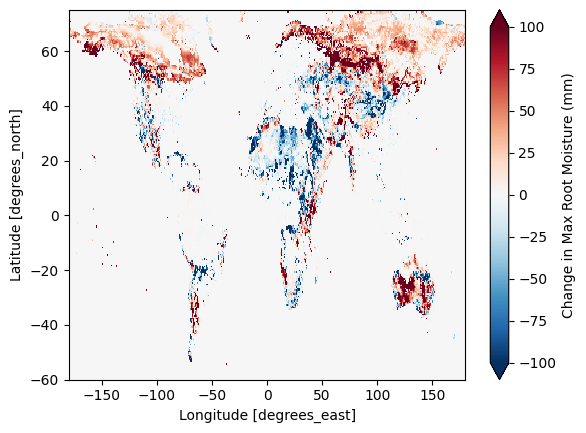

In [107]:
(rm_annual_max_1991_2020 - rm_annual_max_1901_1930).plot(vmin=-100, vmax=100, cmap='RdBu_r', cbar_kwargs={'label': 'Change in Max Root Moisture (mm)'})

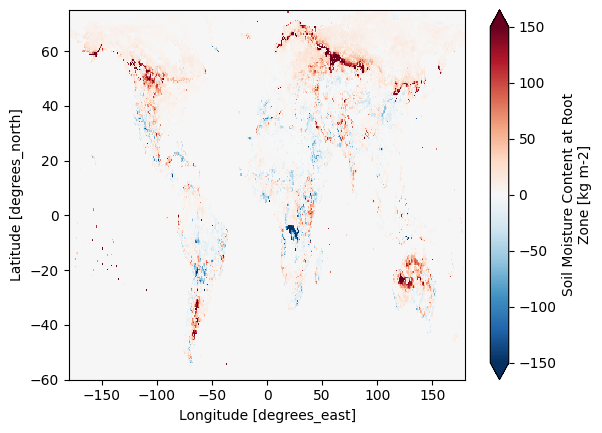

In [7]:
(rm_1991_2020_mean- rm_1961_1990_mean).plot(cmap='RdBu_r', vmin=-150, vmax=150)

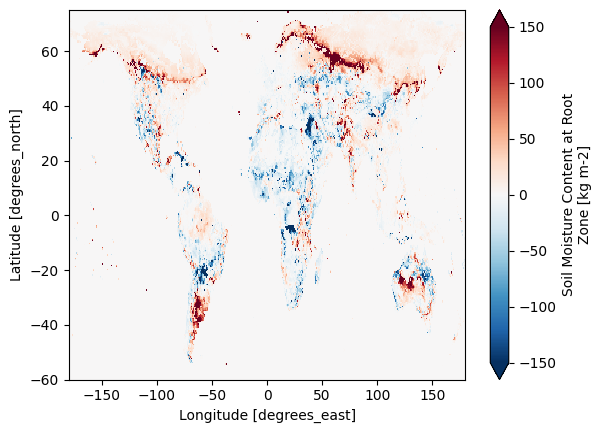

In [8]:
(rm_1991_2020_mean - rm_1901_1930_mean).plot(vmin=-150, vmax=150, cmap='RdBu_r')

In [21]:
# nan mask
nanMask_0p05 = xr.open_dataarray("../data/SR-target/nanMask.nc").rename("nanMask")

# interp like nanMask and apply the mask (has value 1 for cells to mask)
rm_1901_1930_mean_0p05 = rm_1901_1930_mean.interp_like(nanMask_0p05)
rm_1901_1930_mean_0p05 = rm_1901_1930_mean_0p05.where(nanMask_0p05 != 1)

rm_1931_1960_mean_0p05 = rm_1931_1960_mean.interp_like(nanMask_0p05)
rm_1931_1960_mean_0p05 = rm_1931_1960_mean_0p05.where(nanMask_0p05 != 1)

rm_1961_1990_mean_0p05 = rm_1961_1990_mean.interp_like(nanMask_0p05)
rm_1961_1990_mean_0p05 = rm_1961_1990_mean_0p05.where(nanMask_0p05 != 1)

rm_1991_2020_mean_0p05 = rm_1991_2020_mean.interp_like(nanMask_0p05)
rm_1991_2020_mean_0p05 = rm_1991_2020_mean_0p05.where(nanMask_0p05 != 1)

rm_1901_1930_p95_0p05 = rm_1901_1930_p95.interp_like(nanMask_0p05)
rm_1901_1930_p95_0p05 = rm_1901_1930_p95_0p05.where(nanMask_0p05 != 1)

rm_1931_1960_p95_0p05 = rm_1931_1960_p95.interp_like(nanMask_0p05)
rm_1931_1960_p95_0p05 = rm_1931_1960_p95_0p05.where(nanMask_0p05 != 1)

rm_1961_1990_p95_0p05 = rm_1961_1990_p95.interp_like(nanMask_0p05)
rm_1961_1990_p95_0p05 = rm_1961_1990_p95_0p05.where(nanMask_0p05 != 1)

rm_1991_2020_p95_0p05 = rm_1991_2020_p95.interp_like(nanMask_0p05)
rm_1991_2020_p95_0p05 = rm_1991_2020_p95_0p05.where(nanMask_0p05 != 1)

In [47]:
# ressample nanMask to 0.5 degree resolution
nanMask_0p5 = nanMask.coarsen(lat = 10, lon = 10, boundary='trim').mean()

# rm means at 0.5 degree resolution
rm_1901_1930_mean_0p5 = rm_1901_1930_mean.interp_like(nanMask_0p5)
rm_1901_1930_mean_0p5 = rm_1901_1930_mean_0p5.where(nanMask_0p5 != 1)

rm_1931_1960_mean_0p5 = rm_1931_1960_mean.interp_like(nanMask_0p5)
rm_1931_1960_mean_0p5 = rm_1931_1960_mean_0p5.where(nanMask_0p5 != 1)

rm_1961_1990_mean_0p5 = rm_1961_1990_mean.interp_like(nanMask_0p5)
rm_1961_1990_mean_0p5 = rm_1961_1990_mean_0p5.where(nanMask_0p5 != 1)

rm_1991_2020_mean_0p5 = rm_1991_2020_mean.interp_like(nanMask_0p5)
rm_1991_2020_mean_0p5 = rm_1991_2020_mean_0p5.where(nanMask_0p5 != 1)

rm_1901_1930_p95_0p5 = rm_1901_1930_p95.interp_like(nanMask_0p5)
rm_1901_1930_p95_0p5 = rm_1901_1930_p95_0p5.where(nanMask_0p5 != 1)

rm_1931_1960_p95_0p5 = rm_1931_1960_p95.interp_like(nanMask_0p5)
rm_1931_1960_p95_0p5 = rm_1931_1960_p95_0p5.where(nanMask_0p5 != 1)

rm_1961_1990_p95_0p5 = rm_1961_1990_p95.interp_like(nanMask_0p5)
rm_1961_1990_p95_0p5 = rm_1961_1990_p95_0p5.where(nanMask_0p5 != 1)

rm_1991_2020_p95_0p5 = rm_1991_2020_p95.interp_like(nanMask_0p5)
rm_1991_2020_p95_0p5 = rm_1991_2020_p95_0p5.where(nanMask_0p5 != 1)

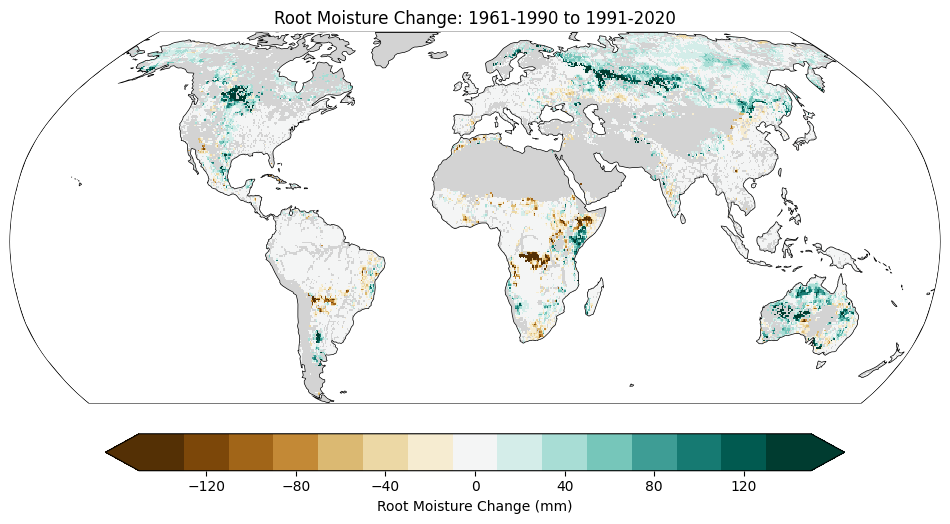

In [23]:
plot_map(rm_1991_2020_p95_0p5 - rm_1961_1990_p95_0p5, title='Root Moisture Change: 1961-1990 to 1991-2020',
         cmap='BrBG', vmin=-150, vmax=150, discrete_cmap=15,
         cbar_label='Root Moisture Change (mm)')

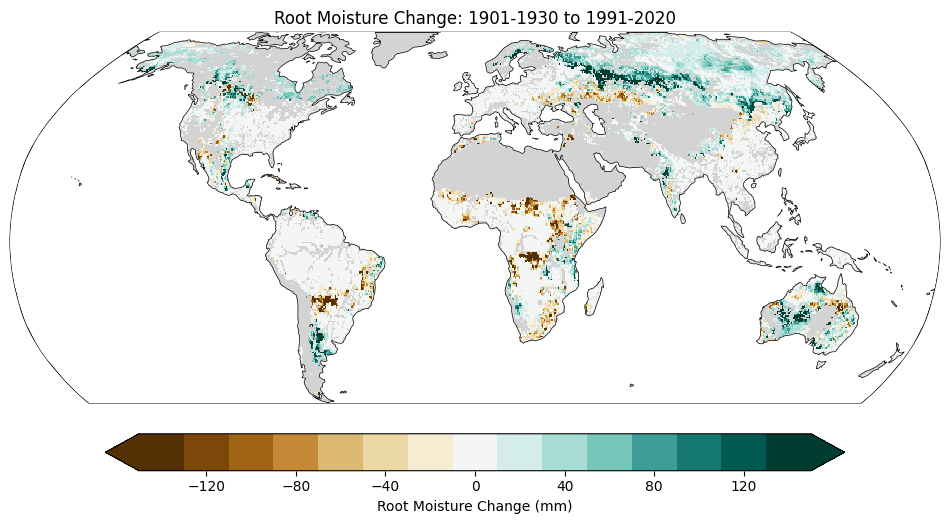

In [24]:
plot_map(rm_1991_2020_p95_0p5 - rm_1901_1930_p95_0p5, title='Root Moisture Change: 1901-1930 to 1991-2020',
         cmap='BrBG', vmin=-150, vmax=150, discrete_cmap=15,
         cbar_label='Root Moisture Change (mm)')

In [25]:
deltaSR20c = xr.open_dataarray("../export/deltaSR_20thC.nc").rename("deltaSR_ml")
sr_1901_1930 = xr.open_dataarray("../export/sr_1901_1930.nc").rename("sr_1901_1930")
deltaSR20c_0p5 = deltaSR20c.interp_like(nanMask0p5)
deltaSR20c_0p5 = deltaSR20c_0p5.where(nanMask0p5 != 1)
sr_1901_1930_0p5 = sr_1901_1930.interp_like(nanMask0p5)
sr_1901_1930_0p5 = sr_1901_1930_0p5.where(nanMask0p5 != 1)

# plot relative change of rootmoist vs deltaSR20c
deltaSR20c_rel_0p5 = deltaSR20c_0p5 / sr_1901_1930_0p5
delta_rm_0p5 = rm_1991_2020_p95_0p5 - rm_1901_1930_p95_0p5
delta_rm_rel_0p5 = delta_rm_0p5 / rm_1901_1930_p95_0p5

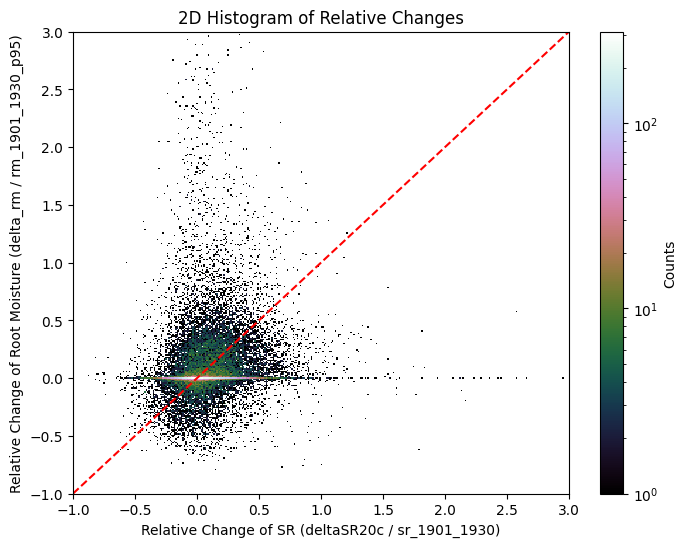

In [43]:
# plot relative change of rootmoist vs deltaSR20c as a 2d histogram
# clip the range to -1 to 1 for both axes
fig, ax = plt.subplots(figsize=(8, 6))
# flatten the data and remove nans
x = deltaSR20c_rel_0p5.values.flatten()
y = delta_rm_rel_0p5.values.flatten()
mask = ~np.isnan(x) & ~np.isnan(y)
x = x[mask]
y = y[mask]
plt.hist2d(x, y, bins=500, cmap='cubehelix', norm=colors.LogNorm())
ax.set_xlim(-1, 3)
ax.set_ylim(-1, 3)
# add a 1:1 line
plt.plot([-1, 3], [-1, 3], color='red', linestyle='--')
plt.xlabel('Relative Change of SR (deltaSR20c / sr_1901_1930)')
plt.ylabel('Relative Change of Root Moisture (delta_rm / rm_1901_1930_p95)')
plt.title('2D Histogram of Relative Changes')
plt.colorbar(label='Counts')
plt.show()

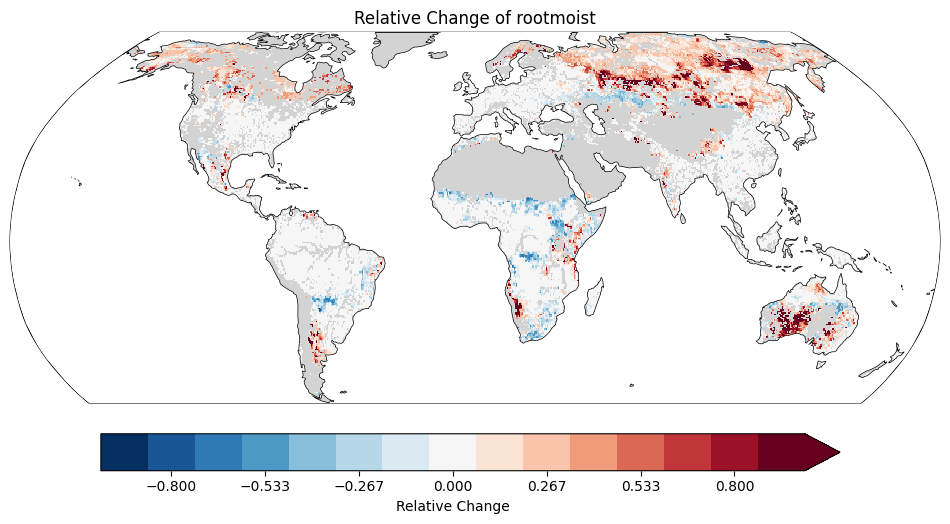

In [44]:
plot_map(delta_rm_rel_0p5, title='Relative Change of rootmoist', cmap='RdBu_r', vmin=-1, vmax=1, discrete_cmap=15, cbar_label='Relative Change')

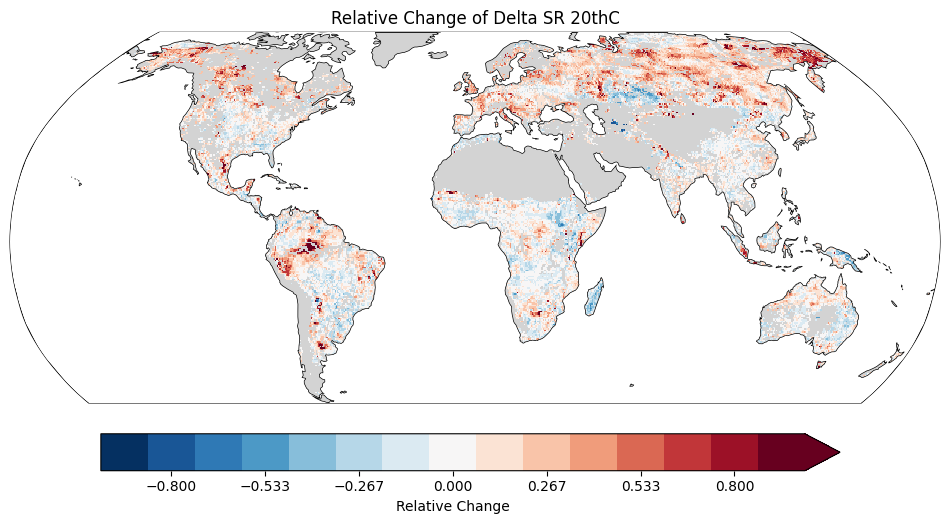

In [45]:
plot_map(deltaSR20c_rel_0p5, title='Relative Change of Delta SR 20thC', cmap='RdBu_r', vmin=-1, vmax=1, discrete_cmap=15, cbar_label='Relative Change')

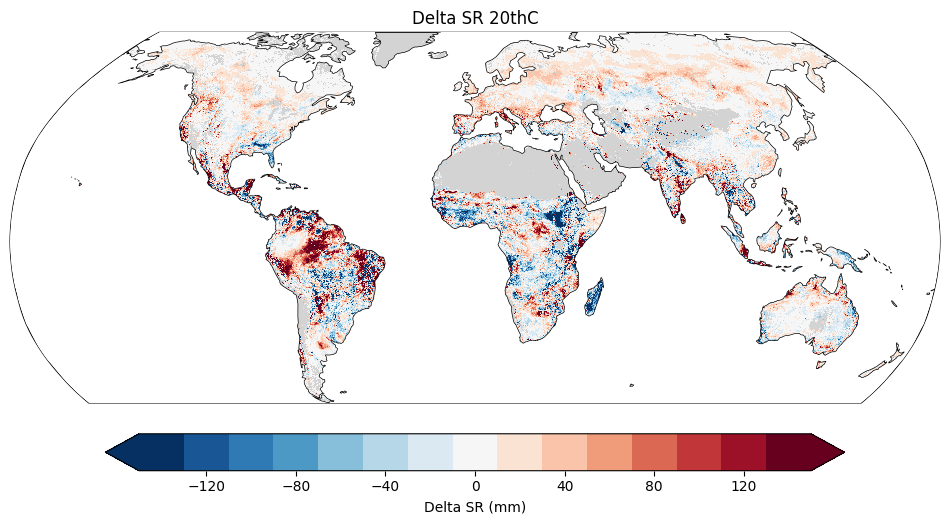

In [108]:
plot_map(deltaSR20c, title='Delta SR 20thC', cmap='RdBu_r', vmin=-150, vmax=150, discrete_cmap=15, cbar_label='Delta SR (mm)')

In [48]:
# resample rm to match nanMask and apply the mask (has value 1 for cells to mask)
rmMasked = rm.interp_like(nanMask_0p5)
rmMasked = rmMasked.where(nanMask_0p5 != 1)

In [49]:
# de-seasonalize and detrend the time series and check stationarity again
# deseasonalize: subtract the monthly mean from each month in the time series for each grid cell
# there are different trends along the entire period
# so we deseasonalize and detrend sperately for different periods, and then check stationarity for each period
# periods: 1901-1927, 1991-2019

monthly_mean_1901_1927 = rm.sel(time=slice('1901', '1927')).groupby('time.month').mean(dim='time')
monthly_mean_1991_2019 = rm.sel(time=slice('1991', '2019')).groupby('time.month').mean(dim='time')

rm_deseasonalized_1901_1927 = rm.sel(time=slice('1901', '1927')).groupby('time.month') - monthly_mean_1901_1927
rm_deseasonalized_1991_2019 = rm.sel(time=slice('1991', '2019')).groupby('time.month') - monthly_mean_1991_2019

# detrend: subtract the linear trend from the time series for each grid cell
from scipy.signal import detrend
def detrend_grid(ts):
    if np.isnan(ts).all(): # if all values are nan, return the ts
        return ts
    # if values are constant, return ts (no change)
    elif np.all(ts == ts[0]):
        return ts
    else:
        return detrend(ts)

# apply the function to each grid cell in the rm_deseasonalized DataArray (time, lat, lon)  along time dimension
rm_deseasonalized_detrended_1901_1927 = xr.apply_ufunc(detrend_grid,
                                                     rm_deseasonalized_1901_1927, input_core_dims=[['time']], output_core_dims=[['time']],
                                                     vectorize=True, dask='parallelized', output_dtypes=[float])
rm_deseasonalized_detrended_1991_2019 = xr.apply_ufunc(detrend_grid,
                                                     rm_deseasonalized_1991_2019, input_core_dims=[['time']], output_core_dims=[['time']],
                                                     vectorize=True, dask='parallelized', output_dtypes=[float])
#rm_deseasonalized_detrended_1901_1927.to_netcdf("../export/rm_deseasonalized_detrended_1901_1927.nc")
#rm_deseasonalized_detrended_1991_2019.to_netcdf("../export/rm_deseasonalized_detrended_1991_2019.nc")

In [50]:
import xarray as xr
import numpy as np
from statsmodels.tsa.stattools import adfuller

def check_stationarity_grid(ts):
    # 1. Pre-filter constant/NaN arrays (much faster than adfuller failing)
    if np.isnan(ts).all() or np.nanstd(ts) == 0:
        return False
    
    try:
        # 2. REDUCE MAXLAG: Default maxlag for 1428 steps is ~23. 
        # Reducing it to 5 or 10 speeds up adfuller significantly with minimal accuracy loss.
        result = adfuller(ts, maxlag=5)
        return result[1] < 0.05
    except ValueError: # Catch edge cases statsmodels sometimes throws
        return False

# apply to 1901-1927 and 1991-2019 separately using a wrapper
def apply_stationarity_check(ts_deseasonalized_detrended):
    # --- Step 1: Stack spatial dimensions ---
    ts_dt_stacked = ts_deseasonalized_detrended.stack(cell=('lat', 'lon'))

    # --- Step 2: Chunk the stacked dimension ---
    ts_dt_stacked = ts_dt_stacked.chunk({'cell': 5000}) 

    # --- Step 3: Apply ufunc ---
    ts_dt_stationarity_stacked = xr.apply_ufunc(
        check_stationarity_grid,
        ts_dt_stacked,
        input_core_dims=[['time']],
        output_core_dims=[[]],      # Output has no time dimension
        vectorize=True,             # Still required to loop over the 'cell' dimension
        dask='parallelized', 
        output_dtypes=[bool]        # Strictly boolean now (no 'None' returned)
    )

    # --- Step 4: Unstack back to original geographical shape ---
    ts_dt_stationarity = ts_dt_stationarity_stacked.unstack('cell')
    
    return ts_dt_stationarity

rm_dt_stationarity_1901_1927 = apply_stationarity_check(rm_deseasonalized_detrended_1901_1927)
rm_dt_stationarity_1991_2019 = apply_stationarity_check(rm_deseasonalized_detrended_1991_2019)

rm_dt_stationarity_1901_1927 = rm_dt_stationarity_1901_1927.compute()
rm_dt_stationarity_1991_2019 = rm_dt_stationarity_1991_2019.compute()

In [51]:
# only on stationary cells,
# calculate lag 1 autocorrelation for each grid cell in the detrended time series for two periods: 1901-1927 and 1991-2019

rm_dt_1901_1927 = rm_deseasonalized_detrended_1901_1927.where(rm_dt_stationarity_1901_1927)
rm_dt_1991_2019 = rm_deseasonalized_detrended_1991_2019.where(rm_dt_stationarity_1991_2019)

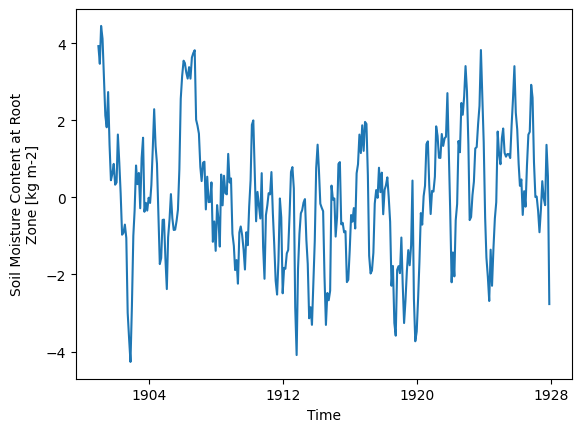

In [52]:
rm_dt_1901_1927.mean(dim=['lat', 'lon']).plot()

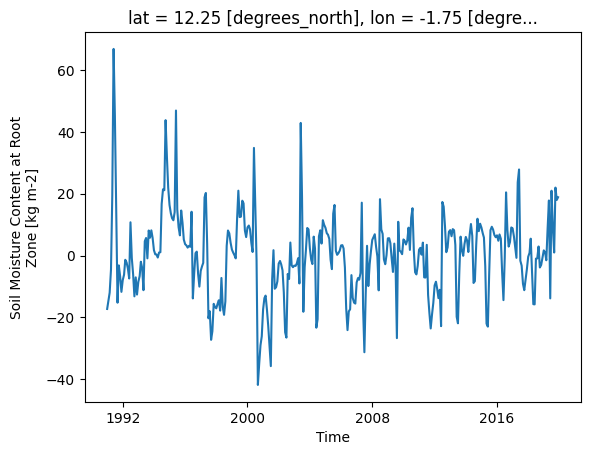

In [53]:
rm_dt_1991_2019.isel(lat=125, lon=356).plot()

In [ ]:
# save rm_dt 
rm_dt_1901_1927.to_netcdf("../export/rm_dt_1901_1927.nc")
rm_dt_1991_2019.to_netcdf("../export/rm_dt_1991_2019.nc")

In [54]:
def calc_AR(da, lag=1):
    return xr.corr(
        da.isel(time=slice(None, -lag)),
        da.isel(time=slice(lag, None)),
        dim="time"
    )

In [58]:
def calc_AR(da, lag=1):
    return xr.corr(
        da,
        da.shift(time=lag),
        dim="time"
    )

In [59]:
ar1_1991_2019 = calc_AR(rm_dt_1991_2019, lag=1)
ar1_1901_1927 = calc_AR(rm_dt_1901_1927, lag=1)

In [60]:
ar1_1991_2019.mean()

<xarray.DataArray 'rootmoist' ()> Size: 8B
array(0.6847426)
Attributes:
    standard_name:  rootmoist
    units:          kg m-2
    long_name:      Soil Moisture Content at Root Zone

In [61]:
ar1_1901_1927.mean()

<xarray.DataArray 'rootmoist' ()> Size: 8B
array(0.67378709)
Attributes:
    standard_name:  rootmoist
    units:          kg m-2
    long_name:      Soil Moisture Content at Root Zone

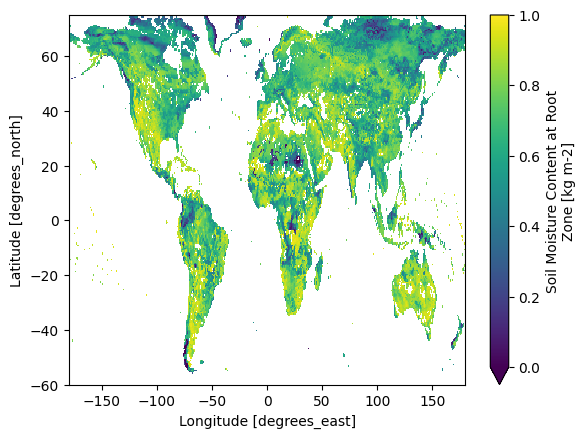

In [64]:
calc_AR(rm_dt_1991_2019, lag=1).plot(vmin=0, vmax=1, cmap='viridis')

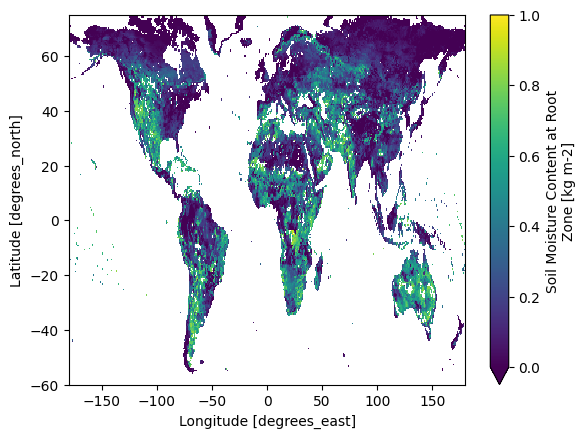

In [66]:
calc_AR(rm_dt_1991_2019, lag=4).plot(vmin=0, vmax=1, cmap='viridis')

In [67]:
memory_1901_1927 = -1/ np.log(ar1_1901_1927)
memory_1991_2019 = -1/ np.log(ar1_1991_2019)

In [68]:
memory6_1901_1927 = -1/ np.log(calc_AR(rm_dt_1901_1927, lag=6))
memory6_1991_2019 = -1/ np.log(calc_AR(rm_dt_1991_2019, lag=6))

In [78]:
memory_change = memory_1991_2019 - memory_1901_1927

(array([  565.,   866.,  1273.,  2133.,  5190., 15398., 17316.,  6901.,
         2854.,  1538.,   997.,   697.]),
 array([-6., -5., -4., -3., -2., -1.,  0.,  1.,  2.,  3.,  4.,  5.,  6.]),
 <BarContainer object of 12 artists>)

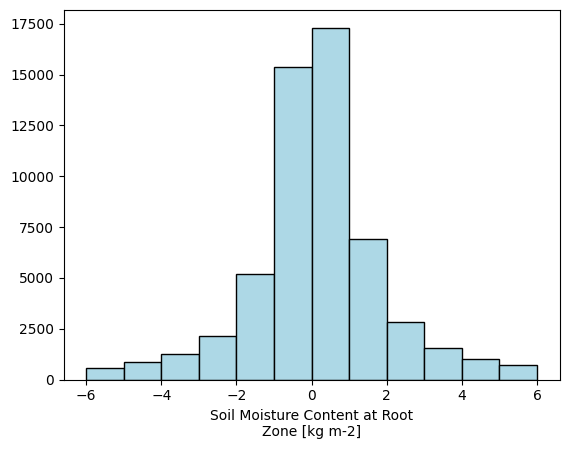

In [70]:
memory_change.plot.hist(bins=np.linspace(-6, 6, 13), color='lightblue', edgecolor='black')

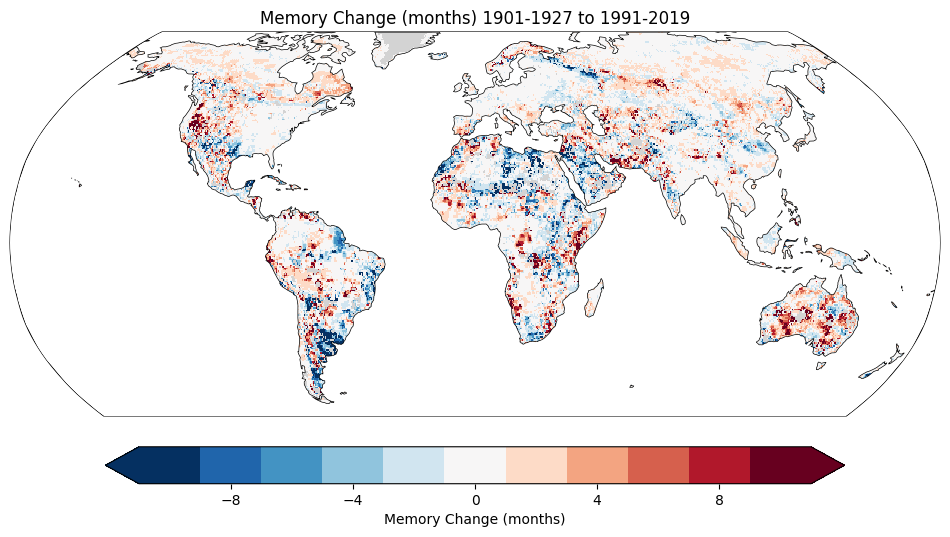

In [71]:
plot_map(memory_change, title='Memory Change (months) 1901-1927 to 1991-2019', cmap='RdBu_r', vmin=-11, vmax=11, cbar_label='Memory Change (months)', discrete_cmap=11)

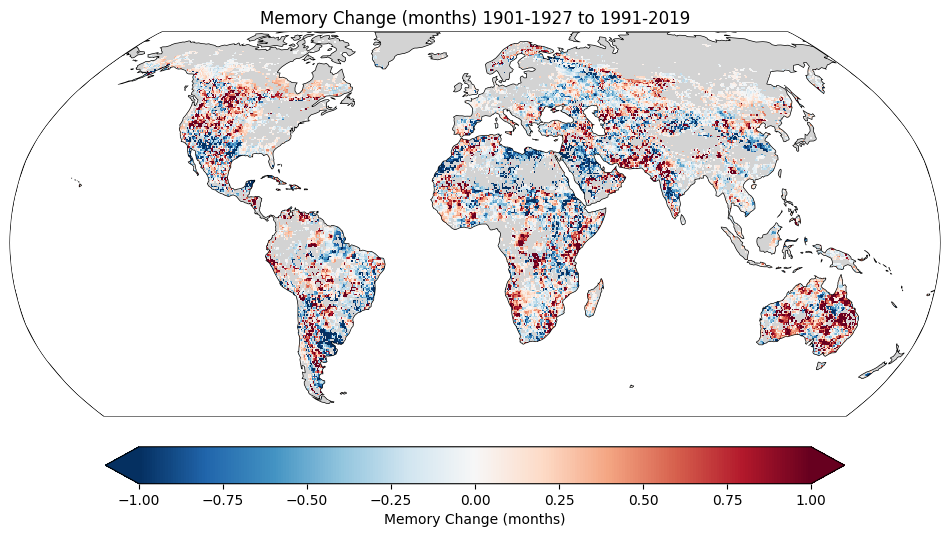

In [72]:
memoryChange6 = memory6_1991_2019 - memory6_1901_1927
plot_map(memoryChange6, title='Memory Change (months) 1901-1927 to 1991-2019', cmap='RdBu_r', vmin=-1, vmax=1, cbar_label='Memory Change (months)')

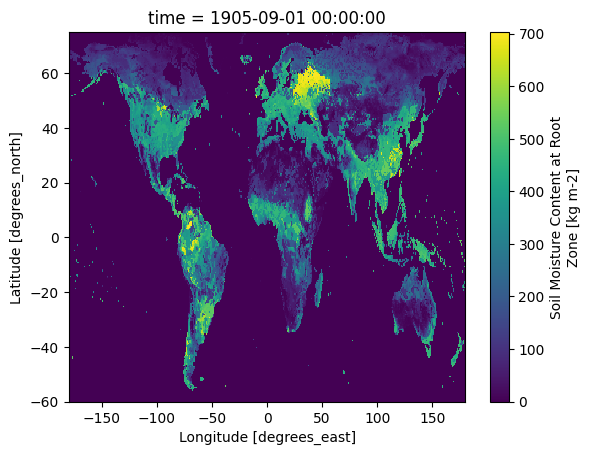

In [73]:
rm.isel(time=56).plot()

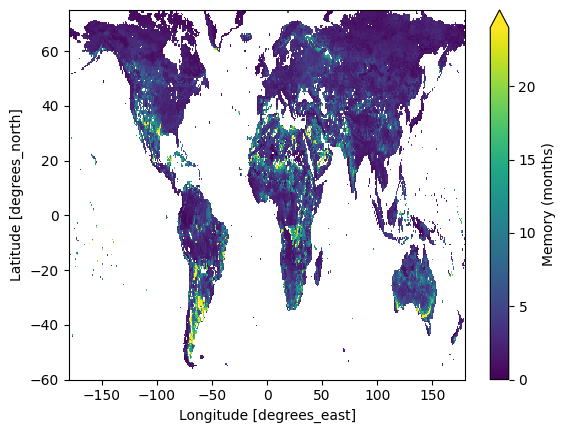

In [74]:
memory_1901_1927.plot(cmap='viridis', vmin=0, vmax=24, cbar_kwargs={'label': 'Memory (months)'})

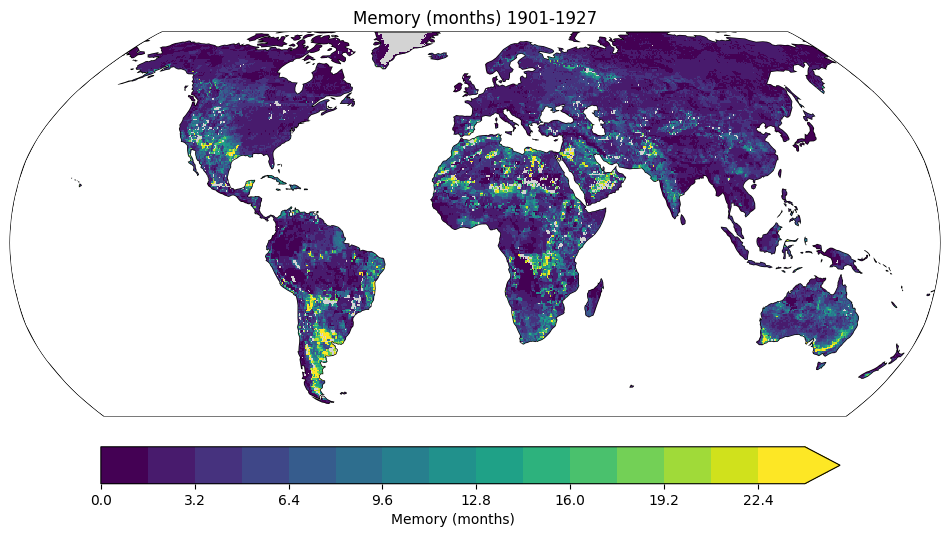

In [75]:
plot_map(memory_1901_1927, title='Memory (months) 1901-1927', cmap='viridis', vmin=0, vmax=24, cbar_label='Memory (months)', discrete_cmap=15)

(array([5.2249e+04, 6.9220e+03, 1.8740e+03, 5.3500e+02, 1.4500e+02,
        2.2000e+01, 3.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([ 0.1144486 ,  6.78306978, 13.45169095, 20.12031213, 26.7889333 ,
        33.45755447, 40.12617565, 46.79479682, 53.463418  , 60.13203917,
        66.80066035]),
 <BarContainer object of 10 artists>)

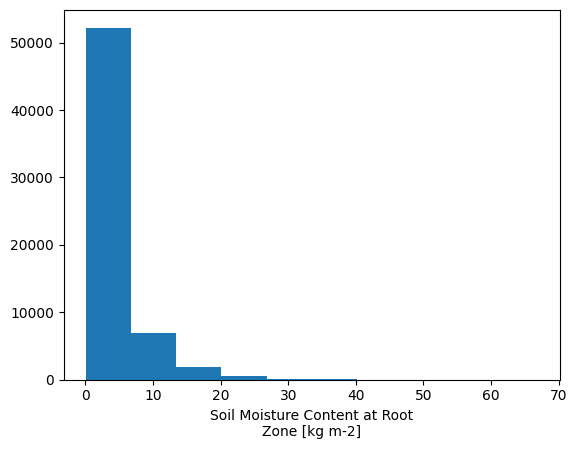

In [76]:
memory_1901_1927.where(memory_1901_1927.values != np.inf).plot.hist()

In [ ]:
da = da.chunk({"time": -1, "lat": 45, "lon": 90})

lag1_autocorr = xr.corr(
    da.isel(time=slice(None, -1)),
    da.isel(time=slice(1, None)),
    dim="time"
)

In [ ]:
# apply AR1 calculation to each period
rm_ar1_1901_1930 = calculate_ar1(rm.sel(time=slice('1901-01-01', '1930-12-31')))
rm_ar1_1931_1960 = calculate_ar1(rm.sel(time=slice('1931-01-01', '1960-12-31')))
rm_ar1_1961_1990 = calculate_ar1(rm.sel(time=slice('1961-01-01', '1990-12-31')))
rm_ar1_1991_2020 = calculate_ar1(rm.sel(time=slice('1991-01-01', '2019-12-31')))